In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.model_selection import cross_val_score, KFold

df = pd.read_csv("bigmart_clean.csv")
enc = pd.read_csv("bigmart_encoded.csv")
test = pd.read_csv("test.csv")
X = enc.drop(columns=["Item_Outlet_Sales"])
y = enc["Item_Outlet_Sales"]
rm = "neg_root_mean_squared_error"

In [2]:
print("lr-", round(-cross_val_score(LinearRegression(), X, y, cv=5, scoring=rm).mean(), 1))
for d in range(3, 9):
    tree = DecisionTreeRegressor(max_depth=d, min_samples_leaf=50, random_state=42)
    print("tree", d, round(-cross_val_score(tree, X, y, cv=5, scoring=rm).mean(), 1))

lr- 1132.6
tree 3 1250.3
tree 4 1117.0


tree 5 1085.9
tree 6 1085.8


tree 7 1092.8
tree 8 1095.8


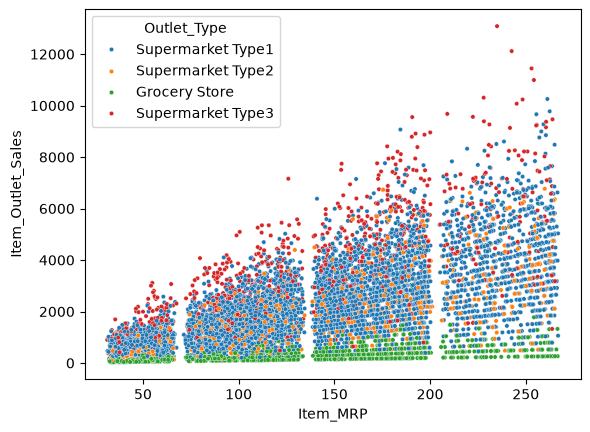

Outlet_Identifier
OUT010     2.38
OUT013    16.00
OUT017    16.66
OUT018    13.85
OUT019     2.44
OUT027    26.61
OUT035    16.97
OUT045    15.58
OUT046    16.19
OUT049    16.63
Name: ratio, dtype: float64

In [3]:
sns.scatterplot(x=df["Item_MRP"], y=df["Item_Outlet_Sales"], hue=df["Outlet_Type"], s=10)
plt.show()
df["ratio"] = df["Item_Outlet_Sales"] / df["Item_MRP"]
df.groupby("Outlet_Identifier")["ratio"].mean().round(2)

In [4]:
X3 = pd.get_dummies(df["Outlet_Identifier"], dtype=float).mul(df["Item_MRP"], axis=0)
print("mult-", round(-cross_val_score(LinearRegression(fit_intercept=False), X3, y, cv=5, scoring=rm).mean(), 1))

oof = np.zeros(len(df))
scores = []
for tr, va in KFold(n_splits=5).split(df):
    lr = LinearRegression(fit_intercept=False).fit(X3.iloc[tr], y.iloc[tr])
    avg = df.iloc[tr].groupby("Outlet_Identifier")["ratio"].mean()
    p2 = df["Outlet_Identifier"].iloc[va].map(avg).values * df["Item_MRP"].iloc[va].values
    oof[va] = (lr.predict(X3.iloc[va]) + p2) / 2
    scores.append(np.sqrt(np.mean((y.iloc[va].values - oof[va]) ** 2)))
print("final-", round(np.mean(scores), 1), np.round(scores, 1))

mult- 1072.6
final- 1072.2 [1086.6 1065.8 1065.3 1068.  1075.2]


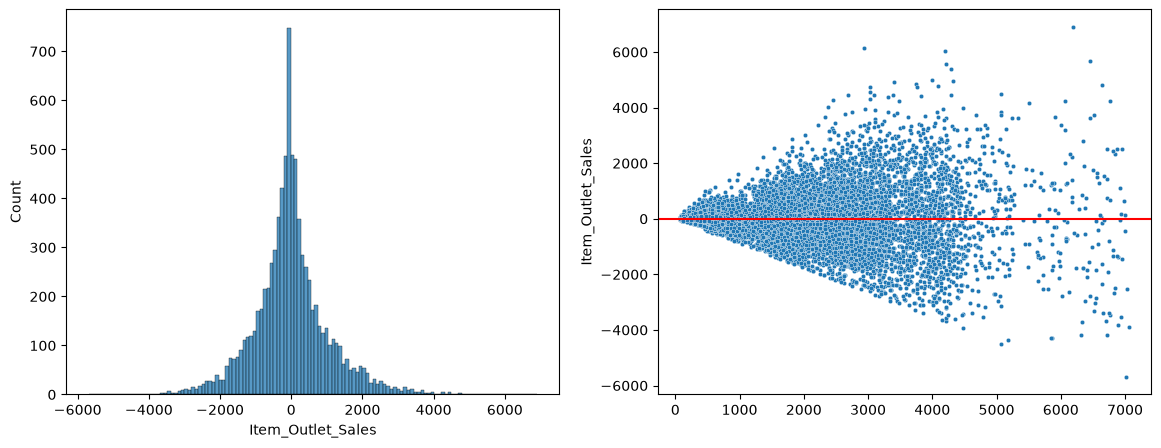

2.363798595786019


In [5]:
res = y - oof
plt.figure(figsize=(14, 5))
plt.subplot(1, 2, 1)
sns.histplot(res)
plt.subplot(1, 2, 2)
sns.scatterplot(x=oof, y=res, s=10)
plt.axhline(0, color="red")
plt.show()
print(res.mean())

In [6]:
lr = LinearRegression(fit_intercept=False).fit(X3, y)
avg = df.groupby("Outlet_Identifier")["ratio"].mean()
print(pd.DataFrame({"lr": lr.coef_, "avg": avg.values}, index=X3.columns).round(2))
Xt = pd.get_dummies(test["Outlet_Identifier"], dtype=float).mul(test["Item_MRP"], axis=0)
test["Item_Outlet_Sales"] = (lr.predict(Xt) + test["Outlet_Identifier"].map(avg).values * test["Item_MRP"].values) / 2
test[["Item_Identifier", "Outlet_Identifier", "Item_Outlet_Sales"]].to_csv("bigmart_submission.csv", index=False)
test["Item_Outlet_Sales"].describe()

           lr    avg
OUT010   2.44   2.38
OUT013  16.42  16.00
OUT017  16.84  16.66
OUT018  14.17  13.85
OUT019   2.42   2.44
OUT027  26.25  26.61
OUT035  17.09  16.97
OUT045  15.56  15.58
OUT046  15.90  16.19
OUT049  16.81  16.63


count    5681.000000
mean     2180.448884
std      1334.540072
min        78.021004
25%      1073.368876
50%      2059.025849
75%      3027.307588
max      7005.031332
Name: Item_Outlet_Sales, dtype: float64